# Regression Tree — When is Both better than Amb only?

Predict delta = mort_both - mort_amb. Negative = both is better.

In [1]:
import sys
from pathlib import Path
_root = Path(".").resolve()
while not (_root / "paths.py").exists():
    _root = _root.parent
sys.path.insert(0, str(_root))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier, plot_tree
from sklearn.model_selection import cross_val_score, cross_val_predict
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

RESULTS_PATH = _root / "data_cluster" / "sobol_no_t2_fixed_pooling" / "results.csv"
df = pd.read_csv(RESULTS_PATH)
print(f"Loaded {len(df)} runs")

UNCERTAINTIES = ["ccp_r1_same_bn_min", "ccp_r1_inter_bn_min", "bcas_rate", "waves_per_day", "wave_duration_min"]

amb  = df[(df["facility_eligibility"] == 0) & (df["ambulance_eligibility"] == 1)].sort_values("scenario").reset_index(drop=True)
both = df[(df["facility_eligibility"] == 1) & (df["ambulance_eligibility"] == 1)].sort_values("scenario").reset_index(drop=True)
assert (amb["scenario"].values == both["scenario"].values).all()

delta = both["death_rate_T1_BCAS"].values - amb["death_rate_T1_BCAS"].values
X = amb[UNCERTAINTIES].astype(float)

print(f"Scenarios: {len(delta)}")
print(f"Delta range: {delta.min():.4f} to {delta.max():.4f}")
print(f"Both better (delta < -0.01): {(delta < -0.01).sum()} ({(delta < -0.01).mean():.1%})")
print(f"Neutral (|delta| <= 0.01): {((delta >= -0.01) & (delta <= 0.01)).sum()}")
print(f"Both worse (delta > 0.01): {(delta > 0.01).sum()} ({(delta > 0.01).mean():.1%})")

Loaded 98304 runs
Scenarios: 24576
Delta range: -0.6667 to 0.5000
Both better (delta < -0.01): 6408 (26.1%)
Neutral (|delta| <= 0.01): 16627
Both worse (delta > 0.01): 1541 (6.3%)


## Regression Tree — Predict delta magnitude

depth= 1: R²=0.1103 ± 0.0239


depth= 2: R²=0.1889 ± 0.0270


depth= 3: R²=0.2231 ± 0.0275


depth= 4: R²=0.2531 ± 0.0284


depth= 5: R²=0.2764 ± 0.0290


...

depth=11: R²=0.2945 ± 0.0268


depth=12: R²=0.2934 ± 0.0279


depth=13: R²=0.2890 ± 0.0294


depth=14: R²=0.2859 ± 0.0294


depth=15: R²=0.2853 ± 0.0291


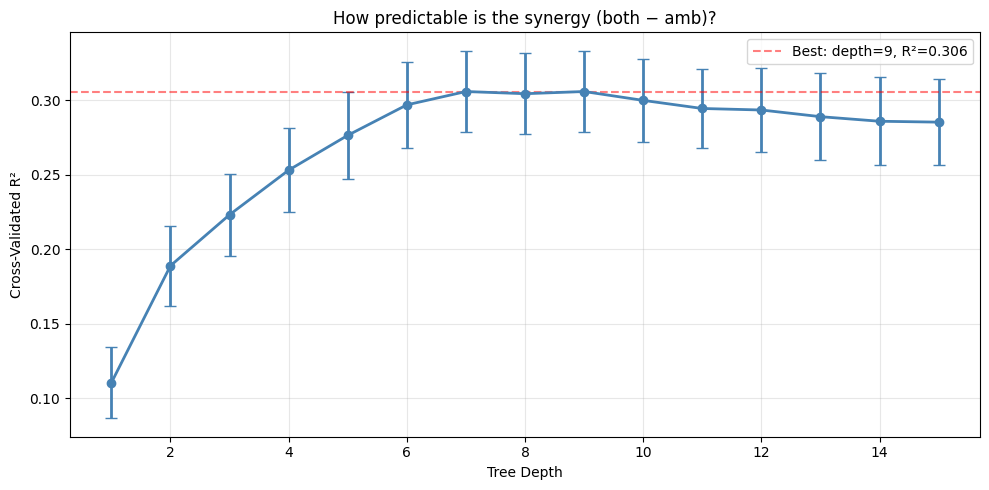


Best depth: 9, R² = 0.3059


In [2]:
depths = list(range(1, 16))
cv_means = []
cv_stds = []

for d in depths:
    tree = DecisionTreeRegressor(max_depth=d, min_samples_leaf=20, random_state=42)
    scores = cross_val_score(tree, X, delta, cv=10, scoring="r2")
    cv_means.append(scores.mean())
    cv_stds.append(scores.std())
    print(f"depth={d:2d}: R²={scores.mean():.4f} ± {scores.std():.4f}")

fig, ax = plt.subplots(figsize=(10, 5))
ax.errorbar(depths, cv_means, yerr=cv_stds, capsize=4, marker="o", color="steelblue", linewidth=2)
ax.set_xlabel("Tree Depth")
ax.set_ylabel("Cross-Validated R²")
ax.set_title("How predictable is the synergy (both − amb)?")
ax.grid(True, alpha=0.3)

best_d = depths[np.argmax(cv_means)]
best_r2 = max(cv_means)
ax.axhline(best_r2, color="red", linestyle="--", alpha=0.5, label=f"Best: depth={best_d}, R²={best_r2:.3f}")
ax.legend()
plt.tight_layout()
plt.show()

print(f"\nBest depth: {best_d}, R² = {best_r2:.4f}")

## Best Tree Visualization

Train R² = 0.2655


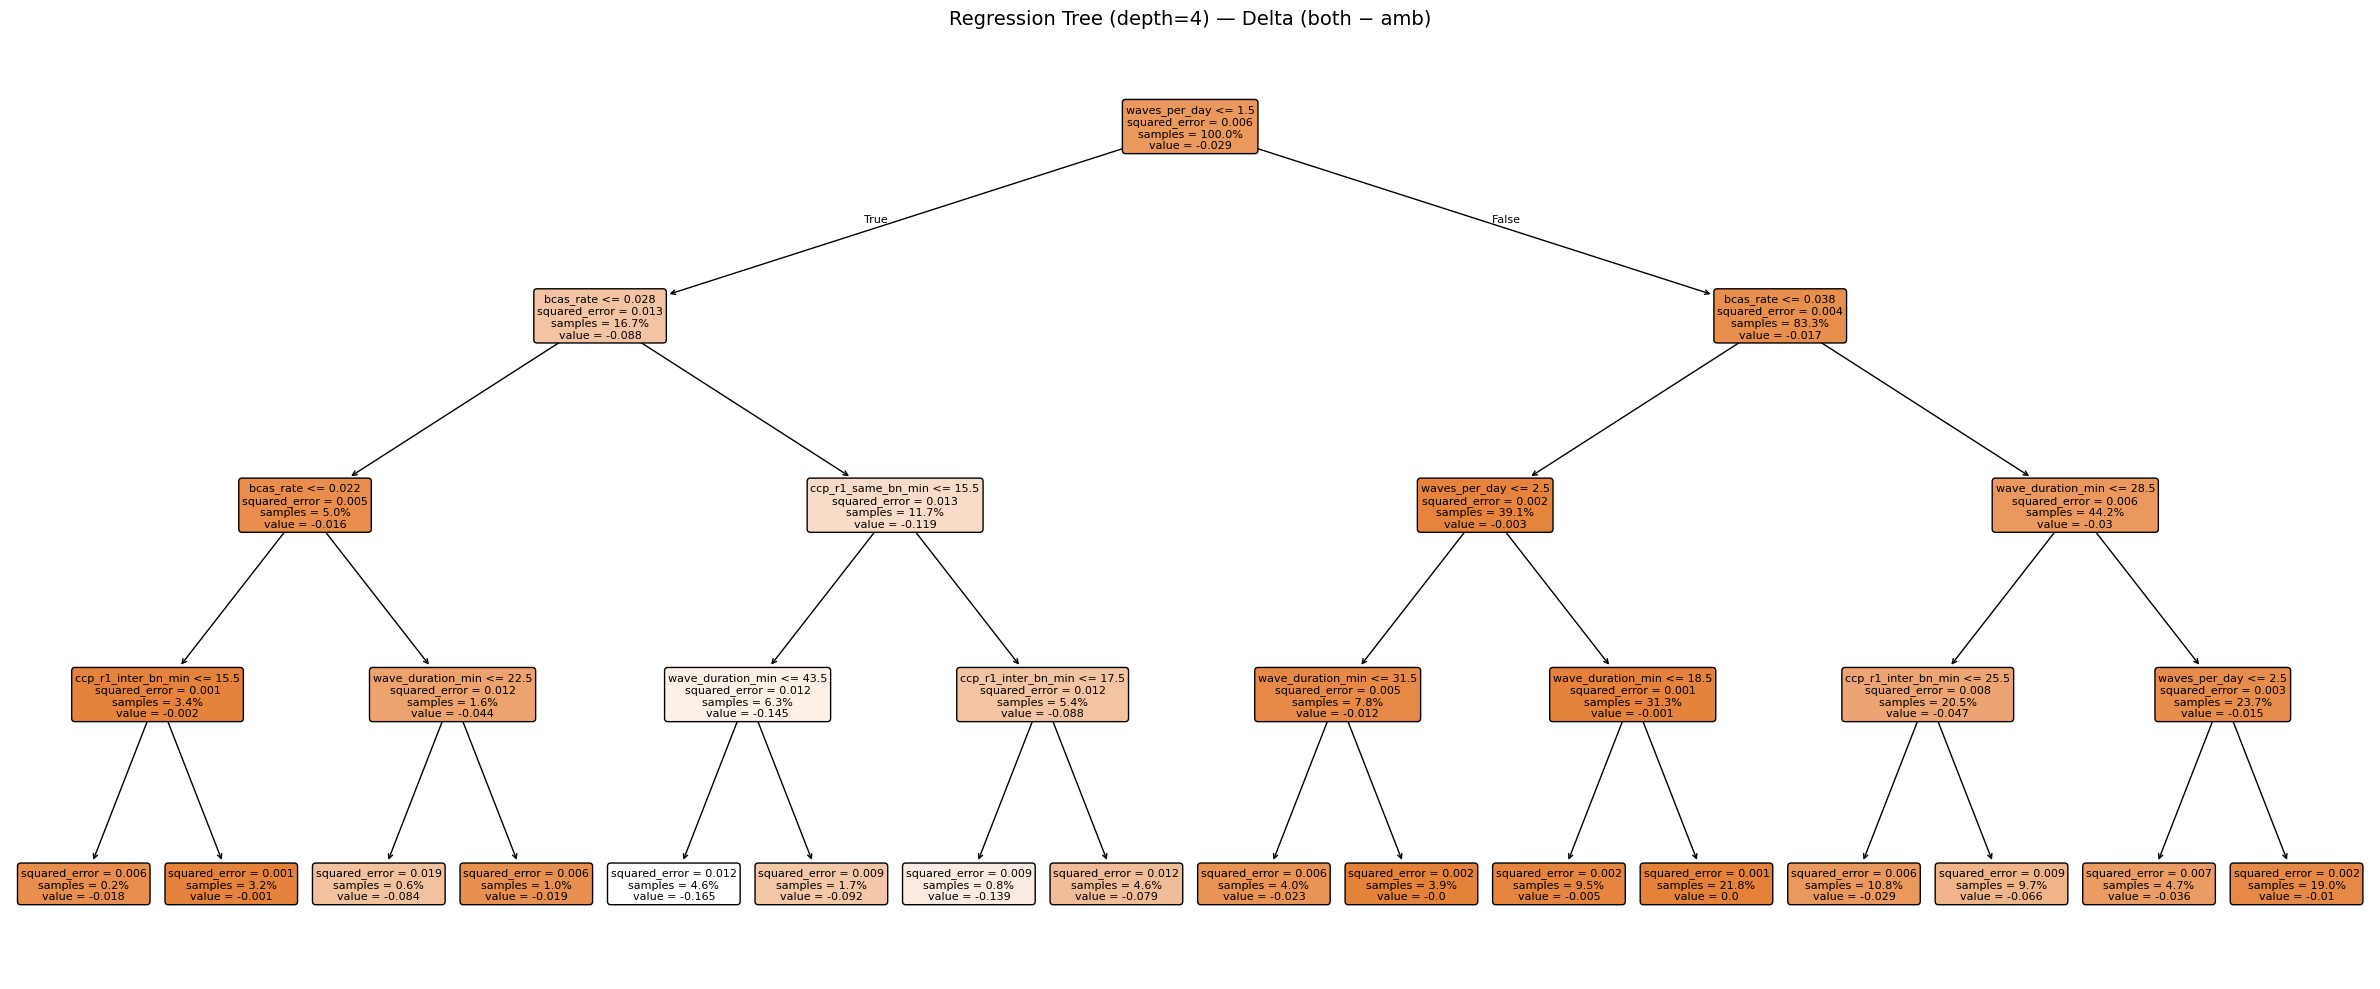

In [3]:
best_tree = DecisionTreeRegressor(max_depth=min(best_d, 4), min_samples_leaf=20, random_state=42)
best_tree.fit(X, delta)
print(f"Train R² = {best_tree.score(X, delta):.4f}")

fig, ax = plt.subplots(figsize=(24, 10))
plot_tree(best_tree, feature_names=UNCERTAINTIES, filled=True, rounded=True,
          fontsize=8, ax=ax, proportion=True)
ax.set_title(f"Regression Tree (depth={min(best_d, 4)}) — Delta (both − amb)", fontsize=14)
plt.tight_layout()
plt.show()

## Feature Importance

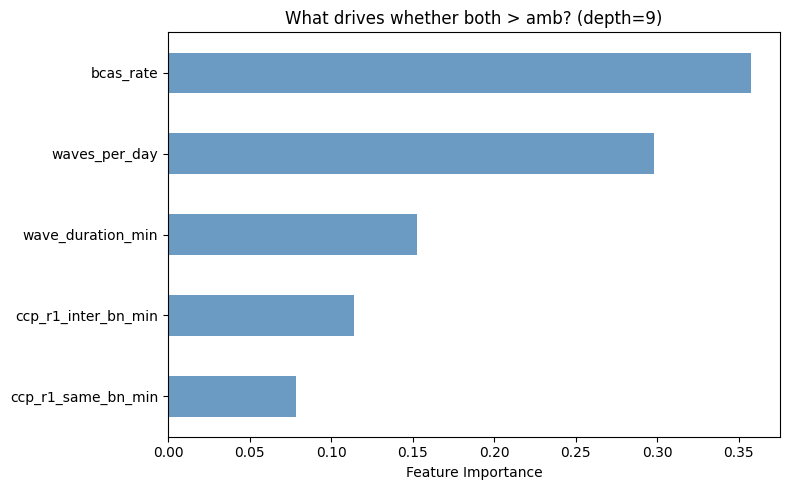

bcas_rate             0.3573
waves_per_day         0.2978
wave_duration_min     0.1525
ccp_r1_inter_bn_min   0.1138
ccp_r1_same_bn_min    0.0786


In [4]:
best_tree_full = DecisionTreeRegressor(max_depth=best_d, min_samples_leaf=20, random_state=42)
best_tree_full.fit(X, delta)

imp = pd.Series(best_tree_full.feature_importances_, index=UNCERTAINTIES).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 5))
imp.plot.barh(ax=ax, color="steelblue", alpha=0.8)
ax.set_xlabel("Feature Importance")
ax.set_title(f"What drives whether both > amb? (depth={best_d})")
plt.tight_layout()
plt.show()

print(imp.sort_values(ascending=False).to_string(float_format="%.4f"))

## Classification Tree — Both better vs not

Both better: 6408 / 24576 (26.1%)



Classification Tree depth=3
CV accuracy: 0.795 ± 0.011
              precision    recall  f1-score   support

  Not better       0.85      0.88      0.86     18168
 Both better       0.62      0.54      0.58      6408

    accuracy                           0.80     24576
   macro avg       0.73      0.71      0.72     24576
weighted avg       0.79      0.80      0.79     24576



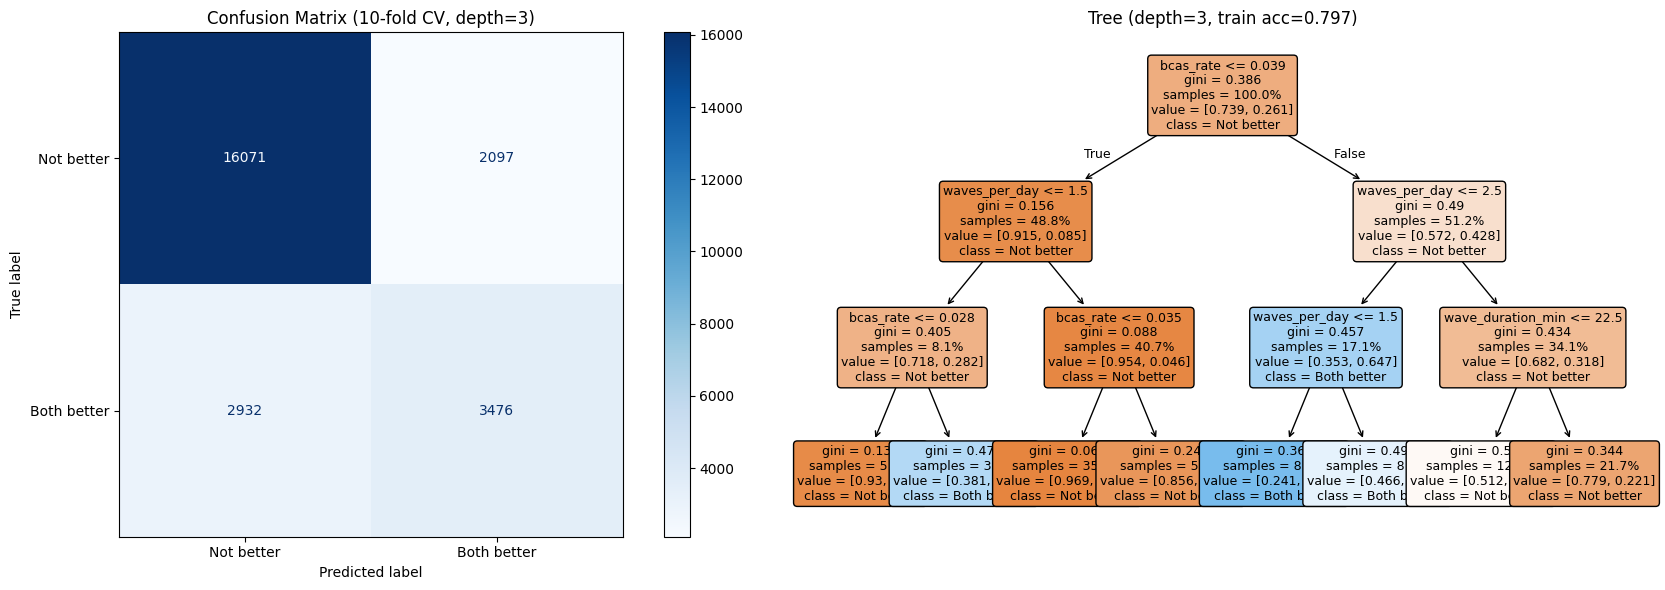

Feature importance:
bcas_rate             0.5996
waves_per_day         0.3061
wave_duration_min     0.0942
ccp_r1_same_bn_min    0.0000
ccp_r1_inter_bn_min   0.0000



Classification Tree depth=4
CV accuracy: 0.813 ± 0.008
              precision    recall  f1-score   support

  Not better       0.85      0.90      0.88     18168
 Both better       0.67      0.56      0.61      6408

    accuracy                           0.81     24576
   macro avg       0.76      0.73      0.74     24576
weighted avg       0.81      0.81      0.81     24576



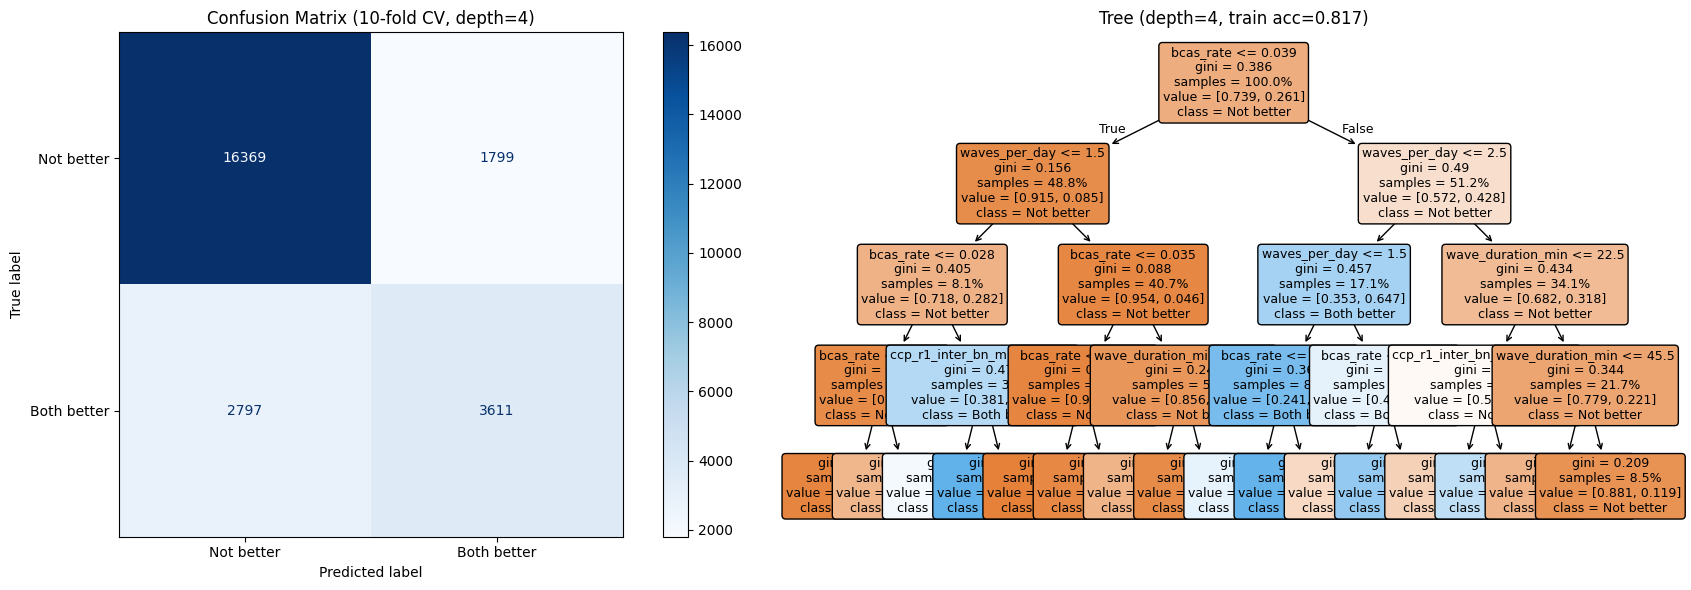

Feature importance:
bcas_rate             0.5833
waves_per_day         0.2718
wave_duration_min     0.1141
ccp_r1_inter_bn_min   0.0307
ccp_r1_same_bn_min    0.0000



Classification Tree depth=5
CV accuracy: 0.819 ± 0.010
              precision    recall  f1-score   support

  Not better       0.87      0.90      0.88     18168
 Both better       0.67      0.60      0.64      6408

    accuracy                           0.82     24576
   macro avg       0.77      0.75      0.76     24576
weighted avg       0.81      0.82      0.82     24576



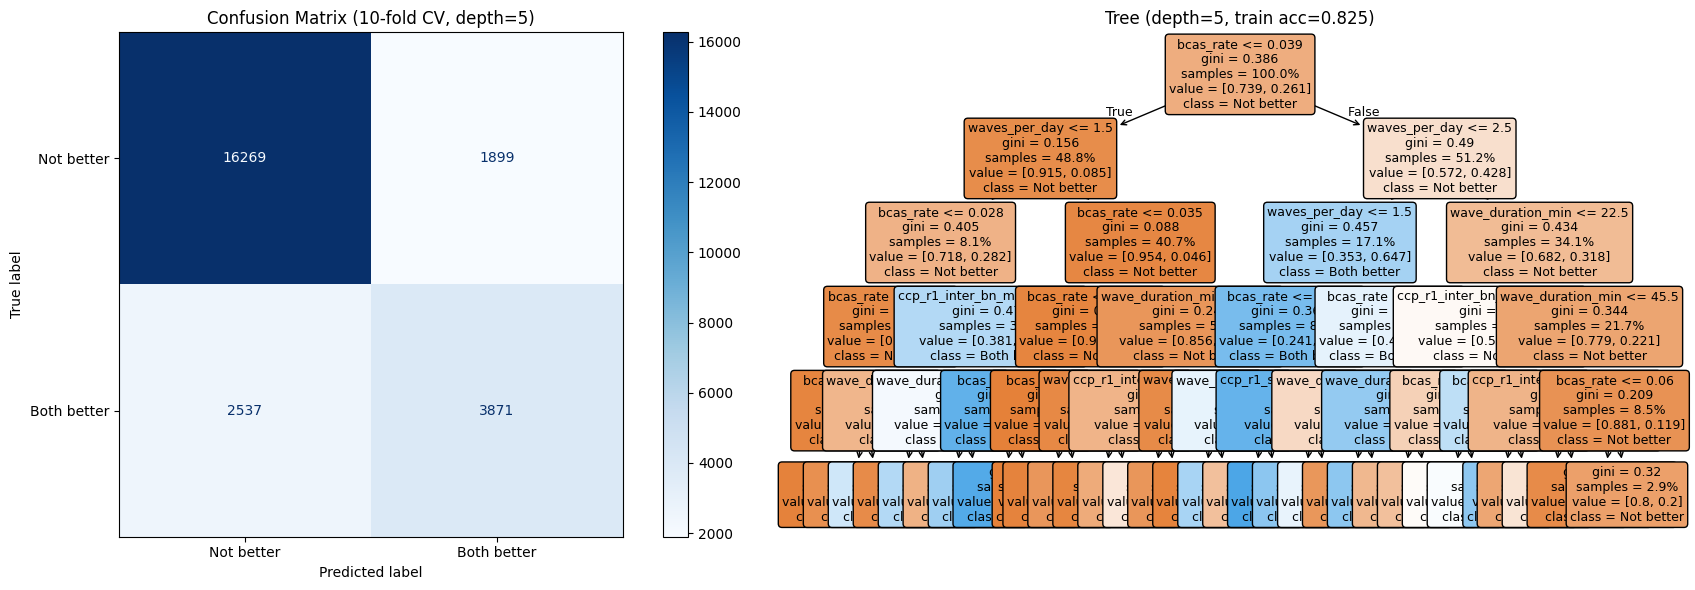

Feature importance:
bcas_rate             0.5460
waves_per_day         0.2526
wave_duration_min     0.1454
ccp_r1_inter_bn_min   0.0459
ccp_r1_same_bn_min    0.0100


In [5]:
y_class = (delta < -0.01).astype(int)  # 1 = both is better
print(f"Both better: {y_class.sum()} / {len(y_class)} ({y_class.mean():.1%})")

for depth in [3, 4, 5]:
    clf = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=20, random_state=42)
    cv_scores = cross_val_score(clf, X, y_class, cv=10, scoring="accuracy")
    y_pred = cross_val_predict(clf, X, y_class, cv=10)

    print(f"\n{'='*60}")
    print(f"Classification Tree depth={depth}")
    print(f"{'='*60}")
    print(f"CV accuracy: {cv_scores.mean():.3f} ± {cv_scores.std():.3f}")
    print(classification_report(y_class, y_pred, target_names=["Not better", "Both better"]))

    fig, axes = plt.subplots(1, 2, figsize=(18, 6))
    cm = confusion_matrix(y_class, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=["Not better", "Both better"]).plot(ax=axes[0], cmap="Blues")
    axes[0].set_title(f"Confusion Matrix (10-fold CV, depth={depth})")

    clf.fit(X, y_class)
    plot_tree(clf, feature_names=UNCERTAINTIES, class_names=["Not better", "Both better"],
              filled=True, rounded=True, fontsize=9, ax=axes[1], proportion=True)
    axes[1].set_title(f"Tree (depth={depth}, train acc={clf.score(X, y_class):.3f})")
    plt.tight_layout()
    plt.show()

    imp_clf = pd.Series(clf.feature_importances_, index=UNCERTAINTIES).sort_values(ascending=False)
    print(f"Feature importance:")
    print(imp_clf.to_string(float_format="%.4f"))

## Predicted vs Actual

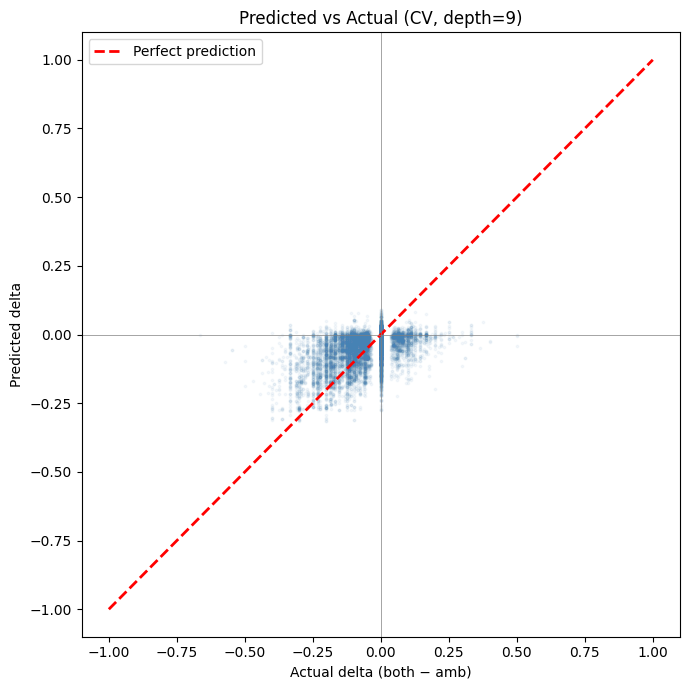

MAE: 0.0371
RMSE: 0.0658


In [6]:
y_pred_reg = cross_val_predict(DecisionTreeRegressor(max_depth=best_d, min_samples_leaf=20, random_state=42), X, delta, cv=10)

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(delta, y_pred_reg, alpha=0.05, s=3, color="steelblue")
ax.plot([-1, 1], [-1, 1], "r--", linewidth=2, label="Perfect prediction")
ax.axhline(0, color="grey", linewidth=0.5)
ax.axvline(0, color="grey", linewidth=0.5)
ax.set_xlabel("Actual delta (both − amb)")
ax.set_ylabel("Predicted delta")
ax.set_title(f"Predicted vs Actual (CV, depth={best_d})")
ax.legend()
plt.tight_layout()
plt.show()

residuals = delta - y_pred_reg
print(f"MAE: {np.abs(residuals).mean():.4f}")
print(f"RMSE: {np.sqrt((residuals**2).mean()):.4f}")